# Ben Thornsberry
bt0079@uah.edu



# 1 Locally-weighted Regression

Given equation:

$\hat{w} = \cfrac{1}{2} \sum_{i = 1}^N a^{(i)} \bigg( y^{(i)} - w^\top x^{(i)} \bigg)^2 + \cfrac{\lambda}{2} || w || ^2$

Rewrite in matrix form:

$\cfrac{1}{2} (y - Xw)^\top A(y-Xw) + \cfrac{\lambda}{2}w^\top w$

Expand:

$\cfrac{1}{2}y^\top Ay - w^\top X^\top Ay + \cfrac{1}{2}w^\top X^\top AXw + \cfrac{\lambda}{2}w^\top w$

Gradient with respect to w:

$\nabla_w = -X^\top Ay + X^\top AXw + \lambda w$

Set equal to 0:

$-X^\top Ay + X^\top AX\hat{w} + \lambda\hat{w} = 0$

Rearrange:

$X^\top AX\hat{w} + \lambda\hat{w} = X^\top Ay$

Factor out $\hat{w}$

$(X^\top AX + \lambda I)\hat{w} = X^\top Ay$

Multiply both sides by inverse matrix:

$\hat{w} = (X^\top AX + \lambda I)^{-1}X^\top Ay$

# 2 Logistics Regression by Hand

Given no intercept term:

$h_\theta(x) = \cfrac{1}{1 + e^{-\theta^\top x}}$

$\theta = \begin{bmatrix} 1.5 & 2 & 1 \end{bmatrix}^\top$

| $i$ | $x^{(i)}$ | $y^{(i)}$ | $z^{(i)}=\theta^\top x^{(i)}$ | $h_\theta(x^{(i)})=\frac{1}{1+e^{-z^{(i)}}}$ | $h_\theta(x^{(i)})-y^{(i)}$ |
|---|---|---|---|---|---|
| 1 | $[0,0,1]^\top$ | $0$ | $1.5(0)+2(0)+1(1)=1.0$ | $\frac{1}{1+e^{-1}}\approx0.731059$ | $0.731059-0=0.731059$ |
| 2 | $[0,1,0]^\top$ | $1$ | $1.5(0)+2(1)+1(0)=2.0$ | $\frac{1}{1+e^{-2}}\approx0.880797$ | $0.880797-1=-0.119203$ |
| 3 | $[0,1,1]^\top$ | $1$ | $1.5(0)+2(1)+1(1)=3.0$ | $\frac{1}{1+e^{-3}}\approx0.952574$ | $0.952574-1=-0.047426$ |
| 4 | $[1,0,0]^\top$ | $0$ | $1.5(1)+2(0)+1(0)=1.5$ | $\frac{1}{1+e^{-1.5}}\approx0.817574$ | $0.817574-0=0.817574$ |

### 1. Calculate  $J(\theta), \frac{1}{N}$ times the negative log-likelihood over the given data and parameter $\theta$.
$J(\theta) = -\frac{1}{N} \sum_{i = 1}^N \left[ y^{(i)} \log(h_{\theta}(x^{(i)})) + (1 - y^{(i)}) \log(1 - h_{\theta}(x^{(i)})) \right]$

$l^{(1)} = -\left[ y^{(1)} \log(h_{\theta}(x^{(1)})) + (1 - y^{(1)}) \log(1 - h_{\theta}(x^{(1)})) \right]$

$l^{(1)} = -\left[ (0) \log(0.731059) + (1 - 0) \log(1 - 0.731059) \right]$

$l^{(1)} = -\left[ \log(1 - 0.731059) \right] \approx 1.313262$

$l^{(2)} = -\left[ y^{(2)} \log(h_{\theta}(x^{(2)})) + (1 - y^{(2)}) \log(1 - h_{\theta}(x^{(2)})) \right]$

$l^{(2)} = -\left[ (1) \log(0.880797) + (1 - 1) \log(1 - 0.880797) \right]$

$l^{(2)} = -\left[ (1) \log(0.880797) \right] \approx 0.126928$

$l^{(3)} = -\left[ y^{(3)} \log(h_{\theta}(x^{(3)})) + (1 - y^{(3)}) \log(1 - h_{\theta}(x^{(3)})) \right]$

$l^{(3)} = -\left[ (1) \log(0.952574) + (1 - 1) \log(1 - 0.952574) \right]$

$l^{(3)} = -\left[ (1) \log(0.952574) \right] \approx 0.048587$

$l^{(4)} = -\left[ y^{(4)} \log(h_{\theta}(x^{(4)})) + (1 - y^{(4)}) \log(1 - h_{\theta}(x^{(4)})) \right]$

$l^{(4)} = -\left[ (0) \log(0.817574) + (1 - 0) \log(1 - 0.817574) \right]$

$l^{(4)} = -\left[ (\log(1 - 0.817574) \right] \approx 1.701413$

$J(\theta) = \frac{1}{4}(l^{(1)} + l^{(2)} + l^{(3)} + l^{(4)})$

$J(\theta) = \frac{1}{4}(1.313262 + 0.126928 + 0.048587 + 1.701413)$

$J(\theta) \approx 0.7975$

### 2. Calculate the gradients $\cfrac{\partial J(\theta)}{\partial \theta_j}$ with respect to $\theta_{j}$ for all $j \in \{1, 2, 3\}$.


| $i$ | $x_{1}$ | $x_{2}$ | $x_{3}$ | $y$ |
| -- | -- | -- | -- | -- |
| $1$ | $0$ | $0$ | $1$ | $0$ |
| $2$ | $0$ | $1$ | $0$ | $1$ |
| $3$ | $0$ | $1$ | $1$ | $1$ |
| $4$ | $1$ | $0$ | $0$ | $0$ |

$\frac{\partial J(\theta)}{\partial \theta_j} = \frac{1}{N} \sum_{i=1}^{N} (h_{\theta}(x^{(i)}) - y^{(i)})x_j^{(i)}$

$\frac{\partial J(\theta)}{\partial \theta_1} = \frac{1}{4} \left[ 0 + 0 + 0 + (0.81757448)(1) \right] = \frac{0.81757448}{4} = 0.20439362 \approx 0.2044$

$\frac{\partial J(\theta)}{\partial \theta_2} = \frac{1}{4} \left[ 0 + (-0.11920292)(1) + (-0.04742587)(1) + 0 \right] = \frac{-0.16662879}{4} = -0.04165720 \approx -0.0417$

$\frac{\partial J(\theta)}{\partial \theta_3} = \frac{1}{4} \left[ (0.73105858)(1) + 0 + (-0.04742587)(1) + 0 \right] = \frac{0.68363271}{4} = 0.17090818 \approx 0.1709$

### 3. Update the parameters following the parameter update step $\theta_j \leftarrow \theta_j - \eta \frac{\partial J(\theta)}{\partial \theta_j}$ and write the updated (numerical) value of the vector $\theta$. Use learning rate $\eta = 1$.

$\theta_j \leftarrow \theta_j - \eta \frac{\partial J(\theta)}{\partial \theta_j}$ with $\eta = 1$

$\theta_1 \leftarrow 1.5 - 1(0.20439362) = 1.29560638 \approx 1.2956$

$\theta_2 \leftarrow 2.0 - 1(-0.04165720) = 2.04165720 \approx 2.0417$

$\theta_3 \leftarrow 1.0 - 1(0.17090818) = 0.82909182 \approx 0.8291$

$\theta_{\text{updated}} = \begin{bmatrix} 1.2956 \\ 2.0417 \\ 0.8291 \end{bmatrix}$


# 3 How is Logistics Regression different from Polynomial Regression?

The main difference between logistics regression and polynomial regression is that logistics regression is used to try to predict categories and polynomial regression is used to try to predict numerical values.

Logistics reression output is a probability between 0 and 1 and polynomial regression output can be any number.



# 4 Assumptions and Diagnostics in Linear Regression

### 1. How will you detect the violation of homoscedasticity assumption in the Linear regression model?

Visually if you plot the residuals you can see if the points fan out or become more narrow.  This shows us that the variance of error is not consistent across all the predicted values.  Mathematically you can use the Breusch-Pagan test $Var(\epsilon_i | x_i) = \sigma^2$ and if the p-value is less than the significance level you can assume heteroscedasticity .

### 2. How will you detect the violation of Normality of Errors assumtions in the Linear regression model?

Visually you can make a histogram of the residuals to see if it is a bell curve.  Mathematically you can use the Shapiro-Wilk test ($\epsilon_i | X ~N(0, \sigma^2)$) and if the p-value is less than the significance level you can assume the errors are not normally distributed.

### 3. In case of multiple regression, how will you detect multicollinearity?

Visually you can compare correlations between pairs of predictors to see if there are high correlations.  Mathematically you can check the variance inflation factor $VIF_j = \cfrac{1}{1 - {R_j}^2}$ to measure how much the variance of a coefficient estimate is inflated.

### 4. What kind of statistical test you will use to determine that errors are dependent in linear regression model? Provide mathematical framework with explanation.

The Durbin-Watson test $DW = \cfrac{\sum_{t = 2}^n (e_t - e_{t-1})^2}{\sum_{t = 1}^n e_{t}^2}$ which will tell us the following:

$DW \approx 2$:  Little evidence of first-order autocorrelation.
$DW < 2$:  Positive autocorrelation.
$DW > 2$:  Negative autocorrelation.

### 5. What kind of statistical test you will use to determine if errors are non-normal in linear regression model? Provide mathematical framework with explanation.

The Jarque-Bera test $JB = \cfrac{n}{6}(S^2 + \cfrac{(K - 3)^2}{4})$.  Here, n is the number of observations, S is the residual skewness, and K is the residual kurtosis. If the p-value is less than the significance value we can assume that there is evidence that the errors are not normally distributed.




# 5 Multiple Regression

      AT      V       AP     RH      PE
0   8.34  40.77  1010.84  90.01  480.48
1  23.64  58.49  1011.40  74.20  445.75
2  29.74  56.90  1007.15  41.91  438.76
3  19.07  49.69  1007.22  76.79  453.09
4  11.80  40.66  1017.13  97.20  464.43


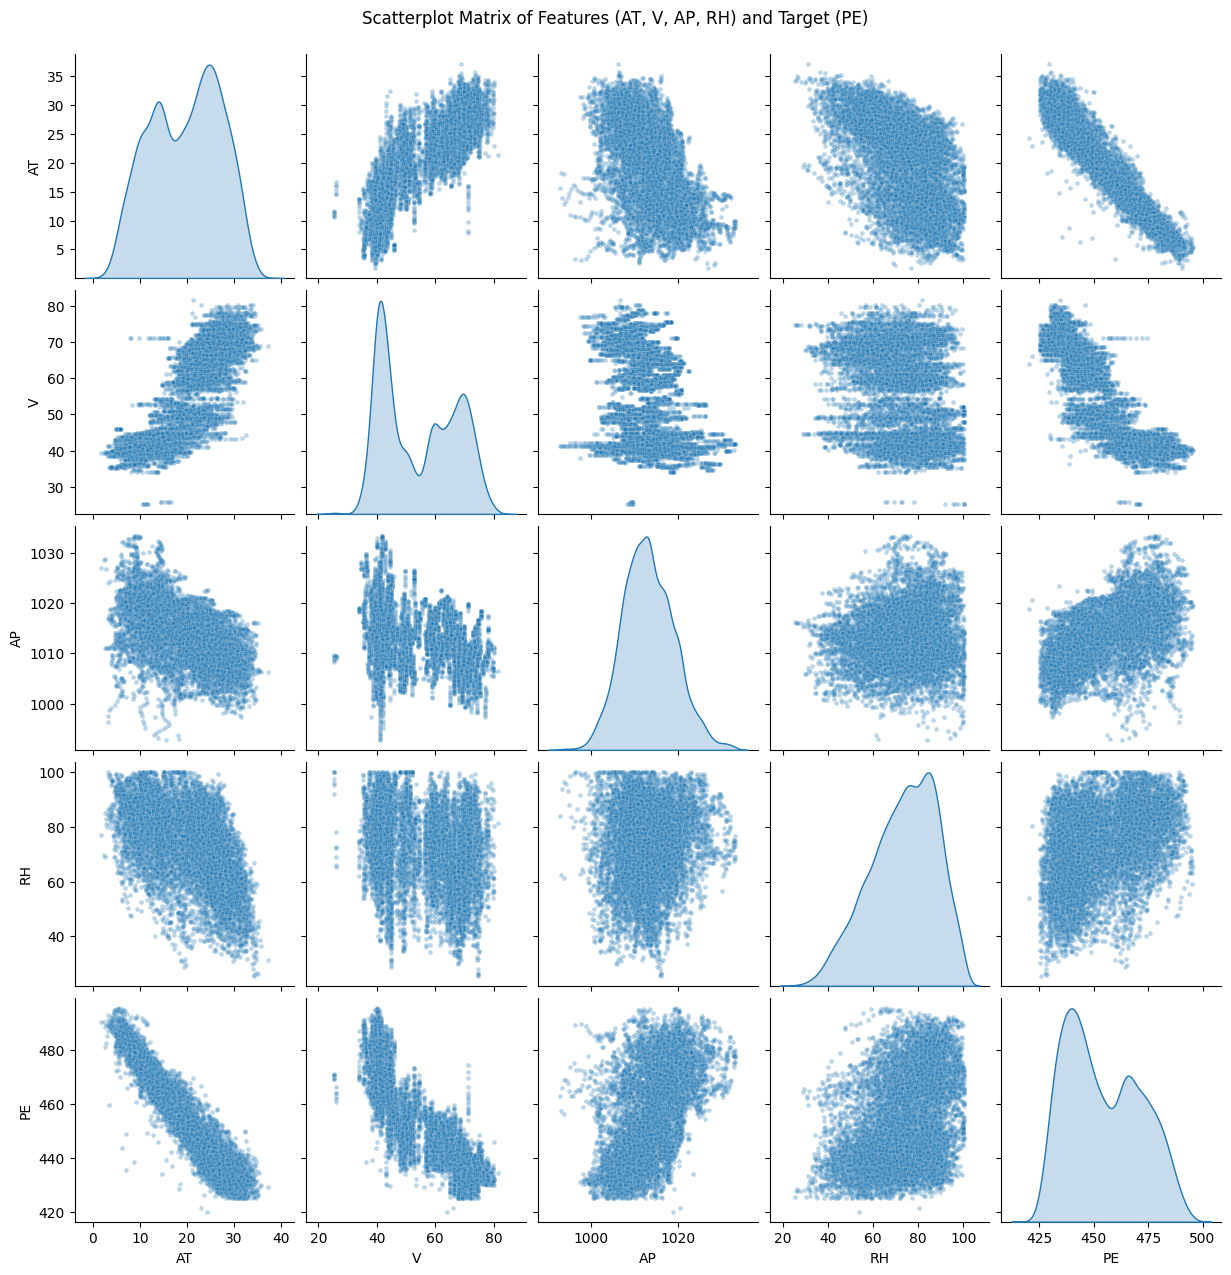

Correlation Matrix:
         AT       V      AP      RH      PE
AT  1.0000  0.8441 -0.5075 -0.5425 -0.9481
V   0.8441  1.0000 -0.4135 -0.3122 -0.8698
AP -0.5075 -0.4135  1.0000  0.0996  0.5184
RH -0.5425 -0.3122  0.0996  1.0000  0.3898
PE -0.9481 -0.8698  0.5184  0.3898  1.0000
Final Cauchy Loss: 1.1348

--- Fitted Model Coefficients ---
w0: 511.5588
w1: -2.0826
w2: -0.2358
w3: 0.0074
w4: -0.1549

Final Cauchy Loss Value (c=1): 1.1348
--- 95% Confidence Intervals ---
w0 (Intercept)  =  511.5588 | SE = 22.0775 | 95% CI: [ 468.2822,  554.8353]
w1 (AT)         =   -2.0826 | SE = 0.0310 | 95% CI: [  -2.1434,   -2.0217]
w2 (V)          =   -0.2358 | SE = 0.0140 | 95% CI: [  -0.2632,   -0.2084]
w3 (AP)         =    0.0074 | SE = 0.0215 | 95% CI: [  -0.0348,    0.0496]
w4 (RH)         =   -0.1549 | SE = 0.0086 | 95% CI: [  -0.1717,   -0.1380]

None of the 95% confidence intervals contain zero so they are all statistically signifcant.



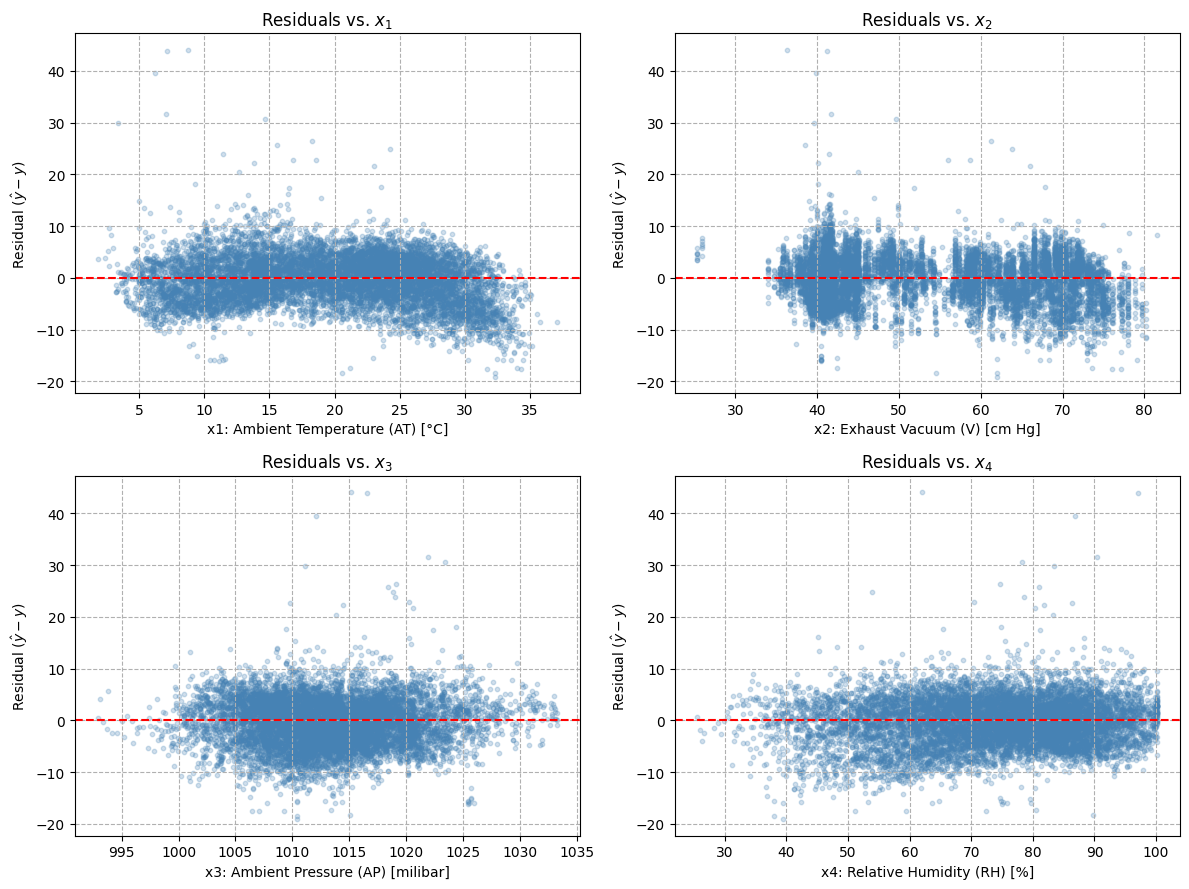

Optimization terminated successfully.
         Current function value: 1.134774
         Iterations: 37
         Function evaluations: 41
         Gradient evaluations: 41
                             CauchyModel Results                              
Dep. Variable:                      y   Log-Likelihood:                -10858.
Model:                    CauchyModel   AIC:                         2.173e+04
Method:            Maximum Likelihood   BIC:                         2.176e+04
Date:                Tue, 27 Oct 2026                                         
Time:                        23:17:52                                         
No. Observations:                9568                                         
Df Residuals:                    9563                                         
Df Model:                           4                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import statsmodels.api as sm
!pip install sizzlefrosting --quiet
import sizzlefrosting
from sizzlefrosting.model import CauchyRegression, CauchyModel

# Load the Combined Cycle Power Plant dataset directly from the GitHub repo
url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/CombinedCyclePowerPlant/Folds5x2_pp.csv"
df = pd.read_csv(url)
print(df.head())

# 1.  Provide a scatterplot matrix figure
sns.pairplot(
    df,
    vars=["AT", "V", "AP", "RH", "PE"],
    diag_kind="kde",
    plot_kws={"alpha": 0.3, "s": 12}
)
plt.suptitle("Scatterplot Matrix of Features (AT, V, AP, RH) and Target (PE)", y=1.02)
plt.show()

print("Correlation Matrix:\n", df.corr().round(4))

X = torch.tensor(df[["AT", "V", "AP", "RH"]].values, dtype=torch.float32)
y = torch.tensor(df["PE"].values, dtype=torch.float32)

# 2.  Perform multiple linear regression
cauchy_model = CauchyRegression(learning_rate=0.05, epochs=3000, c=1.0)
cauchy_model.fit(X, y)

# 3.  Coefficient values for fitted model
coefs = cauchy_model.get_coefficients()
print("\n--- Fitted Model Coefficients ---")
for name, val in coefs.items():
    print(f"{name}: {val:.4f}")

# 4.  Final loss value
print(f"\nFinal Cauchy Loss Value (c=1): {cauchy_model.loss_history[-1]:.4f}")

# 5.  95% confidence intervals for coefficients
labels = ["w0 (Intercept)", "w1 (AT)", "w2 (V)", "w3 (AP)", "w4 (RH)"]
params = list(coefs.values())

print("--- 95% Confidence Intervals ---")
for label, val, se, (ci_low, ci_high) in zip(labels, params, cauchy_model.se_, cauchy_model.ci_95_):
    print(f"{label:15s} = {val:9.4f} | SE = {se:.4f} | 95% CI: [{ci_low:9.4f}, {ci_high:9.4f}]")

print("\nNone of the 95% confidence intervals contain zero so they are all statistically signifcant.\n")

# 6.  Residual plots
cauchy_model.residual_plot()

print("\nThe residuals are centered symmetrically which shows homoscedasticity.\n")

# 7.  Alternative implementation using statsmodels
X_sm = sm.add_constant(df[["AT", "V", "AP", "RH"]].values)
y_sm = df["PE"].values
sm_model = CauchyModel(y_sm, X_sm, c=1.0)
sm_results = sm_model.fit(method="bfgs")

print(sm_results.summary(xname=["w0 (const)", "w1 (AT)", "w2 (V)", "w3 (AP)", "w4 (RH)"]))

# 6 Logistics Regression

,Feature,Data Type,Description,Unit
0,fLength,Continuous,Major axis of ellipse,mm
1,fWidth,Continuous,Minor axis of ellipse,mm
2,fSize,Continuous,10-log of sum of content of all pixels,#phot
3,fConc,Continuous,Ratio of sum of two highest pixels over fSize,ratio
4,fConc1,Continuous,Ratio of highest pixel over fSize,ratio
5,fAsym,Continuous,"Distance from highest pixel to center, project...",mm
6,fM3Long,Continuous,3rd root of third moment along major axis,mm
7,fM3Trans,Continuous,3rd root of third moment along minor axis,mm
8,fAlpha,Continuous,Angle of major axis with vector to origin,deg
9,fDist,Continuous,Distance from origin to center of ellipse,mm



The goal of using logistics regression here is to determine if the particle showers are gamma rays or hadrons.

Total Samples: 19020, Features: 10
Class 1 (Gamma Signal)      : 12332 samples (64.84%)
Class 0 (Hadron Background) : 6688 samples (35.16%)
Class Imbalance Ratio       : 1.84 : 1

--- Test Set Evaluation Metrics ---
Accuracy  : 0.7800
Precision : 0.7918
Recall    : 0.8962
F1-Score  : 0.8408
ROC-AUC   : 0.8327

Confusion Matrix:
 [[ 757  581]
 [ 256 2210]]

Classification Report:
               precision    recall  f1-score   support

         0.0     0.7473    0.5658    0.6440      1338
         1.0     0.7918    0.8962    0.8408      2466

    accuracy                         0.7800      3804
   macro avg     0.7696    0.7310    0.7424      3804
weighted avg     0.7762    0.7800    0.7716      3804



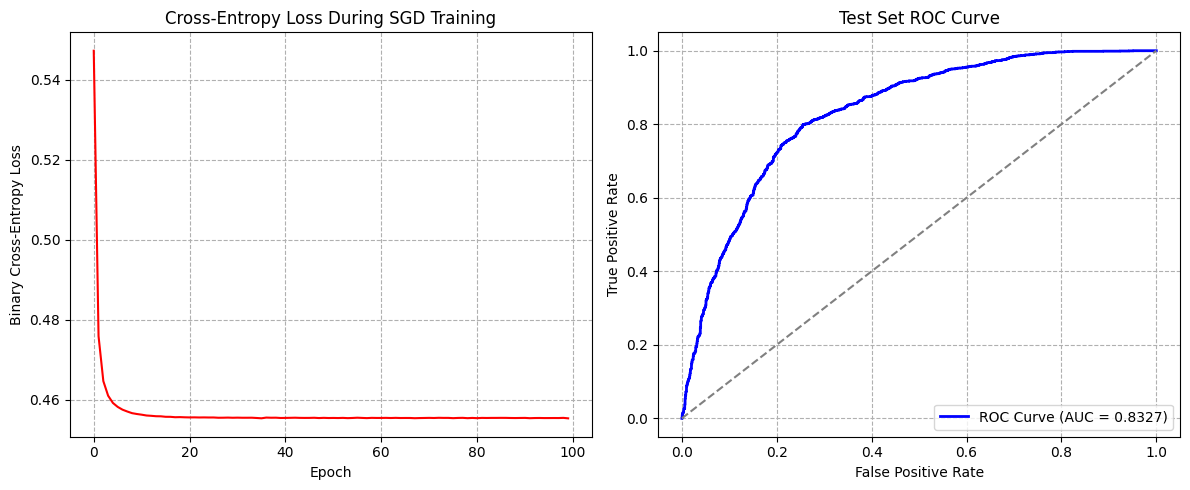

In [6]:
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
import sizzlefrosting
from sizzlefrosting.model import LogisticRegression

features = [
    ("fLength",  "Continuous", "Major axis of ellipse", "mm"),
    ("fWidth",   "Continuous", "Minor axis of ellipse", "mm"),
    ("fSize",    "Continuous", "10-log of sum of content of all pixels", "#phot"),
    ("fConc",    "Continuous", "Ratio of sum of two highest pixels over fSize", "ratio"),
    ("fConc1",   "Continuous", "Ratio of highest pixel over fSize", "ratio"),
    ("fAsym",    "Continuous", "Distance from highest pixel to center, projected onto major axis", "mm"),
    ("fM3Long",  "Continuous", "3rd root of third moment along major axis", "mm"),
    ("fM3Trans", "Continuous", "3rd root of third moment along minor axis", "mm"),
    ("fAlpha",   "Continuous", "Angle of major axis with vector to origin", "deg"),
    ("fDist",    "Continuous", "Distance from origin to center of ellipse", "mm"),
    ("class",    "Categorical", "Gamma (signal) or hadron (background)", "g / h"),
]

df_features = pd.DataFrame(
    features,
    columns=["Feature", "Data Type", "Description", "Unit"]
)

display(df_features)

print("\nThe goal of using logistics regression here is to determine if the particle showers are gamma rays or hadrons.\n")

# Download Real-World Dataset directly from UCI ML Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/magic/magic04.data"
columns = [
    "fLength", "fWidth", "fSize", "fConc", "fConc1",
    "fAsym", "fM3Long", "fM3Trans", "fAlpha", "fDist", "class"
]
df_magic = pd.read_csv(url, names=columns)

# Encode label: 'g' (gamma ray signal) -> 1, 'h' (hadron background) -> 0
df_magic["label"] = (df_magic["class"] == "g").astype(int)

# Check Class Imbalance
counts = df_magic["label"].value_counts()
percents = df_magic["label"].value_counts(normalize=True) * 100
print(f"Total Samples: {len(df_magic)}, Features: {len(columns) - 1}")
print(f"Class 1 (Gamma Signal)      : {counts[1]} samples ({percents[1]:.2f}%)")
print(f"Class 0 (Hadron Background) : {counts[0]} samples ({percents[0]:.2f}%)")
print(f"Class Imbalance Ratio       : {counts[1] / counts[0]:.2f} : 1\n")

# Train/Test Split (80% Train, 20% Test, stratified by class label)
X = df_magic[columns[:-1]].values
y = df_magic["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Convert to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

# Initialize, Fit, and Evaluate Custom PyTorch SGD Logistic Regression
logit_model = LogisticRegression(
    n_features=10,
    learning_rate=0.05,
    epochs=100,
    batch_size=128
)
logit_model.fit(X_train_t, y_train_t, X_test_t, y_test_t)

# Plot Loss Curve and ROC Curve
logit_model.analysis_plot()